In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.anova import anova_lm
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.feature_selection import f_regression, mutual_info_regression, SequentialFeatureSelector
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RepeatedKFold, train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Aesthetics
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
df = pd.read_csv("womens_clothing_regression_dataset.csv")
print(f"Dataset shape: {df.shape}")

candidate_features = [
    'Length_of_Membership',
    'Time_on_App',
    'Avg_Session_Length',
    'Time_on_Website',
    'Annual_Orders',
    'Avg_Order_Value',
    'Age',
    'Rating',
    'Recommended IND',
    'Positive Feedback Count',
    'Review_Length',
    'Review_Word_Count'
]
target = 'Yearly_Amount_Spent'

X_cand = df[candidate_features]
y = df[target]

print(f"Target Variable (Yearly_Amount_Spent): Mean = ${y.mean():.2f}, Std = ${y.std():.2f}")


Dataset shape: (23465, 20)
Target Variable (Yearly_Amount_Spent): Mean = $701.92, Std = $147.12


In [3]:
X_cand_const = sm.add_constant(X_cand)
vif_records = []

for i, col in enumerate(X_cand_const.columns):
    if col == 'const':
        continue
    vif = variance_inflation_factor(X_cand_const.values, i)
    corr_y = df[col].corr(y)
    vif_records.append({
        'Feature': col,
        'Correlation_with_Target': round(corr_y, 4),
        'VIF': round(vif, 2),
        'Multicollinearity_Status': 'High Risk (VIF > 5.0)' if vif > 5.0 else 'Acceptable'
    })

df_vif = pd.DataFrame(vif_records).sort_values(by='Correlation_with_Target', ascending=False)
df_vif.to_csv("feature_vif_and_correlations.csv", index=False)
df_vif


,Feature,Correlation_with_Target,VIF,Multicollinearity_Status
0,Length_of_Membership,0.8452,5.20,High Risk (VIF > 5.0)
4,Annual_Orders,0.7747,2.90,Acceptable
6,Age,0.7726,3.91,Acceptable
1,Time_on_App,0.3451,1.17,Acceptable
5,Avg_Order_Value,0.3419,1.02,Acceptable
2,Avg_Session_Length,0.2446,1.02,Acceptable
7,Rating,0.2100,3.12,Acceptable
8,Recommended IND,0.1791,2.72,Acceptable
9,Positive Feedback Count,0.0472,1.05,Acceptable
10,Review_Length,0.0400,68.77,High Risk (VIF > 5.0)


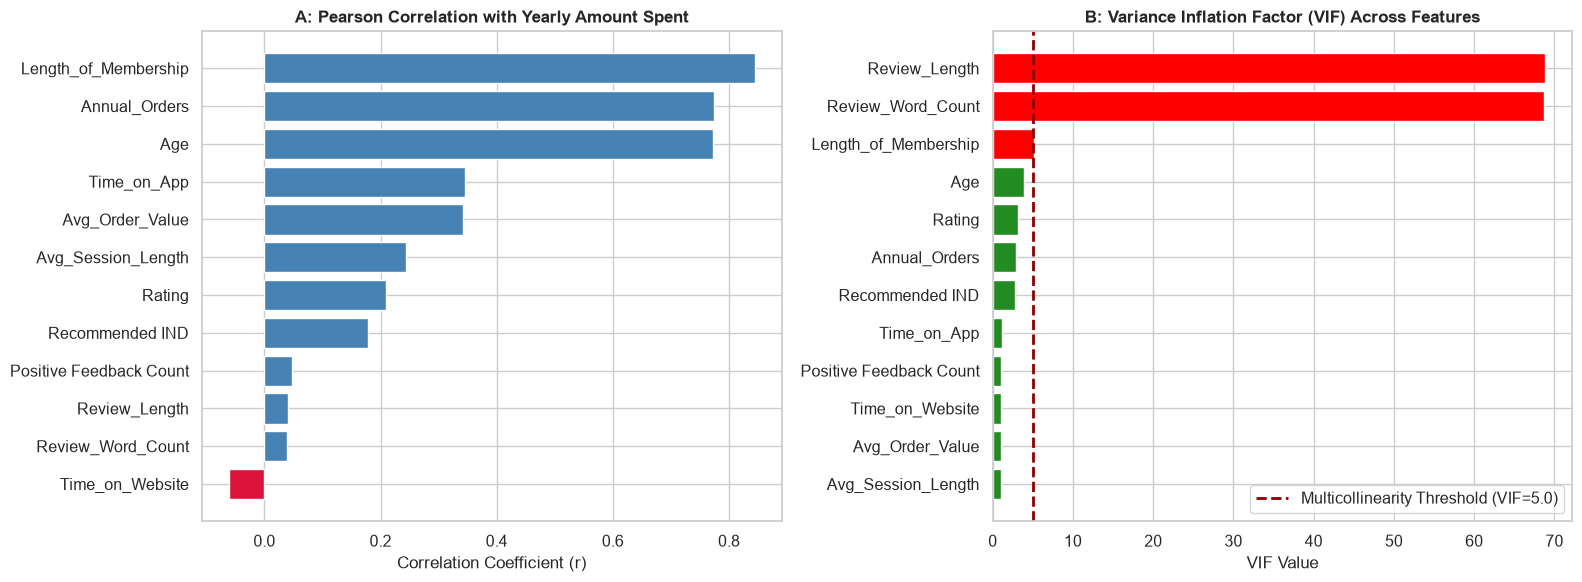

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_corr = df_vif.sort_values(by='Correlation_with_Target', ascending=True)
colors = ['crimson' if c < 0 else 'steelblue' for c in top_corr['Correlation_with_Target']]
axes[0].barh(top_corr['Feature'], top_corr['Correlation_with_Target'], color=colors)
axes[0].set_title("A: Pearson Correlation with Yearly Amount Spent", fontweight='bold')
axes[0].set_xlabel("Correlation Coefficient (r)")

vif_sorted = df_vif.sort_values(by='VIF', ascending=True)
vif_colors = ['red' if v > 5 else 'forestgreen' for v in vif_sorted['VIF']]
axes[1].barh(vif_sorted['Feature'], vif_sorted['VIF'], color=vif_colors)
axes[1].axvline(5.0, color='darkred', linestyle='--', linewidth=2, label='Multicollinearity Threshold (VIF=5.0)')
axes[1].set_title("B: Variance Inflation Factor (VIF) Across Features", fontweight='bold')
axes[1].set_xlabel("VIF Value")
axes[1].legend()

plt.tight_layout()
plt.savefig("feature_correlations_and_vif.png", dpi=300)
plt.show()


In [5]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_cand), columns=candidate_features)

# A. F-Regression
f_stats, p_vals = f_regression(X_cand, y)

# B. Mutual Information
mi_scores = mutual_info_regression(X_cand, y, random_state=42)

# C. LassoCV
lasso = LassoCV(cv=5, random_state=42).fit(X_scaled, y)

# D. Sequential Forward Selector
sfs = SequentialFeatureSelector(LinearRegression(), n_features_to_select=7, direction='forward', cv=5)
sfs.fit(X_cand, y)

df_feat_sel = pd.DataFrame({
    'Feature': candidate_features,
    'F_Statistic': np.round(f_stats, 1),
    'Mutual_Info': np.round(mi_scores, 4),
    'Lasso_Abs_Coef': np.round(np.abs(lasso.coef_), 3),
    'SFS_Selected': sfs.get_support()
}).sort_values(by='F_Statistic', ascending=False)

df_feat_sel.to_csv("feature_selection_comparison.csv", index=False)
df_feat_sel


,Feature,F_Statistic,Mutual_Info,Lasso_Abs_Coef,SFS_Selected
0,Length_of_Membership,58673.3,0.6219,76.660,True
4,Annual_Orders,35216.7,0.4602,37.756,True
6,Age,34751.2,0.4498,18.479,True
1,Time_on_App,3171.7,0.0665,39.855,True
5,Avg_Order_Value,3105.8,0.0972,40.943,True
2,Avg_Session_Length,1493.4,0.0400,22.695,True
7,Rating,1082.0,0.0280,0.281,True
8,Recommended IND,777.6,0.0186,0.000,False
3,Time_on_Website,89.9,0.0000,0.076,False
9,Positive Feedback Count,52.5,0.0016,0.180,False


In [6]:
selected_features = [
    'Length_of_Membership',
    'Time_on_App',
    'Avg_Session_Length',
    'Time_on_Website',
    'Annual_Orders',
    'Avg_Order_Value',
    'Age'
]

df['Inter_App_x_Tenure'] = df['Time_on_App'] * df['Length_of_Membership']
df['Inter_Orders_x_AOV'] = df['Annual_Orders'] * df['Avg_Order_Value']
df['Inter_Age_x_Rating'] = df['Age'] * df['Rating']

X_base = sm.add_constant(df[selected_features])
model_base = sm.OLS(y, X_base).fit()

enhanced_features = selected_features + ['Inter_App_x_Tenure', 'Inter_Orders_x_AOV', 'Inter_Age_x_Rating']
X_enh = sm.add_constant(df[enhanced_features])
model_enh = sm.OLS(y, X_enh).fit()

parsimonious_features = selected_features + ['Inter_App_x_Tenure']
X_pars = sm.add_constant(df[parsimonious_features])
model_pars = sm.OLS(y, X_pars).fit()

print("ANOVA Comparison (Baseline vs Full Interaction Model):")
print(anova_lm(model_base, model_enh))


ANOVA Comparison (Baseline vs Full Interaction Model):
   df_resid           ssr  df_diff        ss_diff           F         Pr(>F)
0   23457.0  1.847538e+07      0.0            NaN         NaN            NaN
1   23454.0  1.787553e+07      3.0  599850.836805  262.349316  1.749892e-167


In [7]:
inter_summary = pd.DataFrame([
    {
        'Interaction Term': 'Time_on_App * Length_of_Membership',
        'Coefficient': f"{model_enh.params['Inter_App_x_Tenure']:.4f}",
        'Std Error': f"{model_enh.bse['Inter_App_x_Tenure']:.4f}",
        't-Statistic': f"{model_enh.tvalues['Inter_App_x_Tenure']:.2f}",
        'p-value': f"{model_enh.pvalues['Inter_App_x_Tenure']:.4e}",
        'Decision': 'Statistically Significant (p < 0.001)'
    },
    {
        'Interaction Term': 'Annual_Orders * Avg_Order_Value',
        'Coefficient': f"{model_enh.params['Inter_Orders_x_AOV']:.4f}",
        'Std Error': f"{model_enh.bse['Inter_Orders_x_AOV']:.4f}",
        't-Statistic': f"{model_enh.tvalues['Inter_Orders_x_AOV']:.2f}",
        'p-value': f"{model_enh.pvalues['Inter_Orders_x_AOV']:.4f}",
        'Decision': 'Not Significant in OLS (p > 0.05)'
    },
    {
        'Interaction Term': 'Age * Rating',
        'Coefficient': f"{model_enh.params['Inter_Age_x_Rating']:.4f}",
        'Std Error': f"{model_enh.bse['Inter_Age_x_Rating']:.4f}",
        't-Statistic': f"{model_enh.tvalues['Inter_Age_x_Rating']:.2f}",
        'p-value': f"{model_enh.pvalues['Inter_Age_x_Rating']:.4f}",
        'Decision': 'Not Significant in OLS (p > 0.05)'
    }
])
inter_summary.to_csv("interaction_terms_statistical_significance.csv", index=False)
inter_summary


,Interaction Term,Coefficient,Std Error,t-Statistic,p-value,Decision
0,Time_on_App * Length_of_Membership,4.0841,0.1456,28.05,2.7931e-170,Statistically Significant (p < 0.001)
1,Annual_Orders * Avg_Order_Value,-0.0019,0.0025,-0.75,0.4510,Not Significant in OLS (p > 0.05)
2,Age * Rating,-0.0127,0.0044,-2.87,0.0042,Not Significant in OLS (p > 0.05)


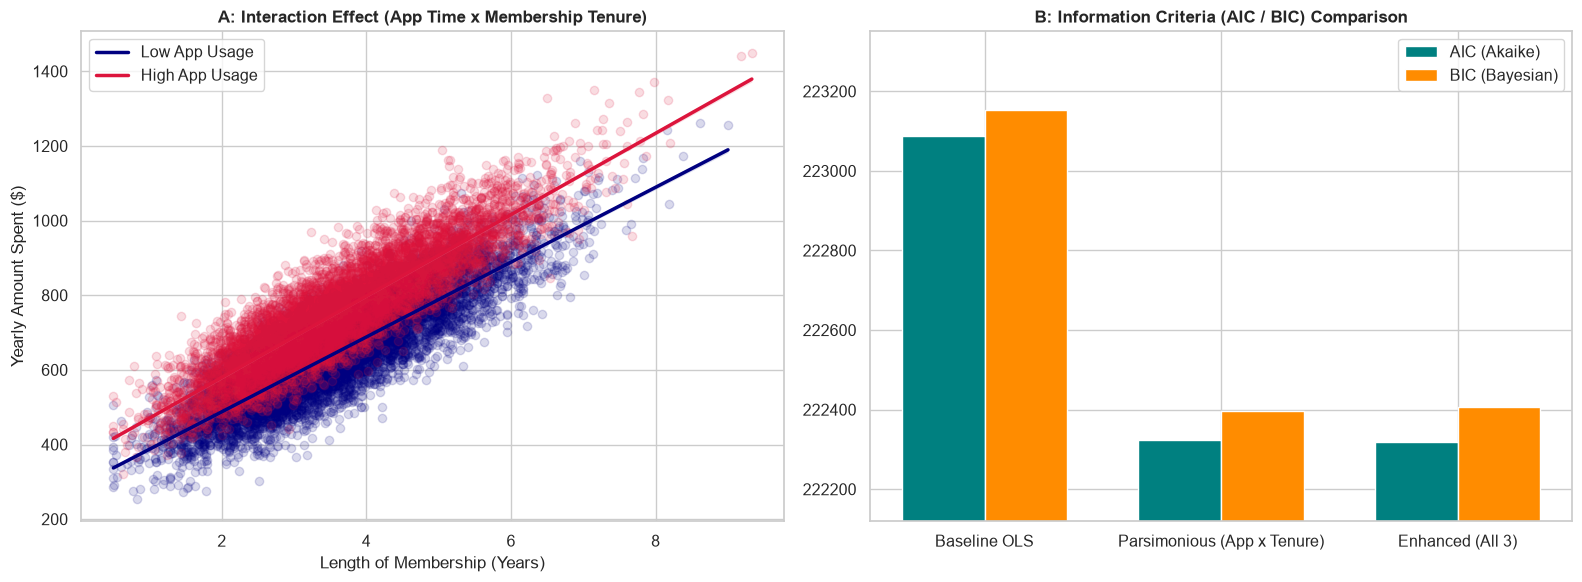

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

app_quantiles = pd.qcut(df['Time_on_App'], q=3, labels=['Low App Time (8-11.8m)', 'Medium App Time (11.8-13m)', 'High App Time (13-16.5m)'])
df['App_Time_Group'] = app_quantiles

sns.regplot(data=df[df['App_Time_Group'] == 'Low App Time (8-11.8m)'], x='Length_of_Membership', y='Yearly_Amount_Spent',
            scatter_kws={'alpha': 0.15, 'color': 'navy'}, line_kws={'color': 'navy', 'linewidth': 2.5, 'label': 'Low App Usage'}, ax=axes[0])
sns.regplot(data=df[df['App_Time_Group'] == 'High App Time (13-16.5m)'], x='Length_of_Membership', y='Yearly_Amount_Spent',
            scatter_kws={'alpha': 0.15, 'color': 'crimson'}, line_kws={'color': 'crimson', 'linewidth': 2.5, 'label': 'High App Usage'}, ax=axes[0])
axes[0].set_title("A: Interaction Effect (App Time x Membership Tenure)", fontweight='bold')
axes[0].set_xlabel("Length of Membership (Years)")
axes[0].set_ylabel("Yearly Amount Spent ($)")
axes[0].legend()

comp_models = ['Baseline OLS', 'Parsimonious (App x Tenure)', 'Enhanced (All 3)']
aics = [model_base.aic, model_pars.aic, model_enh.aic]
bics = [model_base.bic, model_pars.bic, model_enh.bic]
x_pos = np.arange(len(comp_models))
width = 0.35

axes[1].bar(x_pos - width/2, aics, width, label='AIC (Akaike)', color='teal')
axes[1].bar(x_pos + width/2, bics, width, label='BIC (Bayesian)', color='darkorange')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(comp_models)
axes[1].set_title("B: Information Criteria (AIC / BIC) Comparison", fontweight='bold')
axes[1].set_ylim([min(aics) - 200, max(bics) + 200])
axes[1].legend()

plt.tight_layout()
plt.savefig("interaction_effects_visualization.png", dpi=300)
plt.show()


In [9]:
df_cv_robust = pd.read_csv("linear_regression_model_robustness_cv.csv")
print("Robustness Cross-Validation Performance Across 25 Iterations:")
df_cv_robust.groupby('Model_Specification')[['R2_Score', 'RMSE', 'MAE']].agg(['mean', 'std']).round(4)


Robustness Cross-Validation Performance Across 25 Iterations:


R2_Score             RMSE  \
                                                       mean     std     mean   
Model_Specification                                                            
1. Baseline Linear Regression (Selected Features)    0.9636  0.0009  28.0688   
2. Interaction Linear Regression (with App x Te...   0.9647  0.0009  27.6168   
3. Ridge Regression (L2 Regularized)                 0.9647  0.0009  27.6167   
4. Lasso Regression (L1 Regularized)                 0.9641  0.0009  27.8477   

                                                                MAE          
                                                       std     mean     std  
Model_Specification                                                          
1. Baseline Linear Regression (Selected Features)   0.2860  22.3114  0.1910  
2. Interaction Linear Regression (with App x Te...  0.2833  21.9389  0.1920  
3. Ridge Regression (L2 Regularized)                0.2833  21.9389  0.1920  
4. Lasso Regression (L1 Regularized)                0.2934  22.1325  0.2072

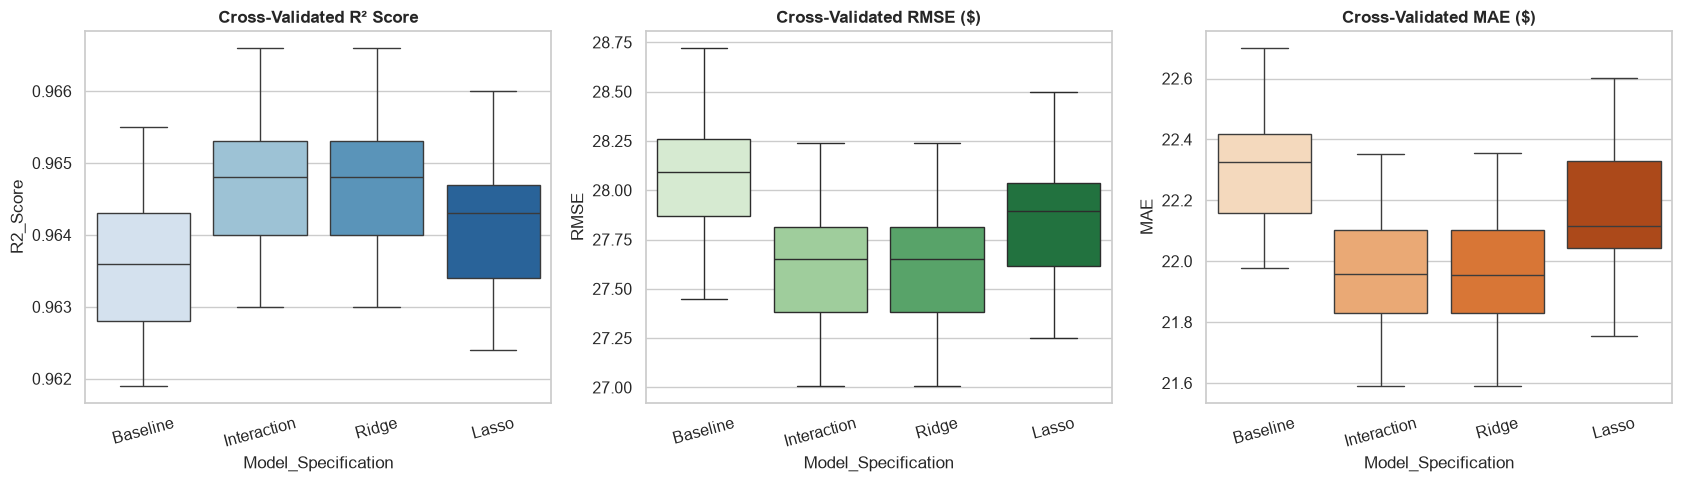

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.boxplot(data=df_cv_robust, x='Model_Specification', y='R2_Score', hue='Model_Specification', palette='Blues', legend=False, ax=axes[0])
axes[0].set_title("Cross-Validated R² Score", fontweight='bold')
axes[0].set_xticks(range(4))
axes[0].set_xticklabels(['Baseline', 'Interaction', 'Ridge', 'Lasso'], rotation=15)

sns.boxplot(data=df_cv_robust, x='Model_Specification', y='RMSE', hue='Model_Specification', palette='Greens', legend=False, ax=axes[1])
axes[1].set_title("Cross-Validated RMSE ($)", fontweight='bold')
axes[1].set_xticks(range(4))
axes[1].set_xticklabels(['Baseline', 'Interaction', 'Ridge', 'Lasso'], rotation=15)

sns.boxplot(data=df_cv_robust, x='Model_Specification', y='MAE', hue='Model_Specification', palette='Oranges', legend=False, ax=axes[2])
axes[2].set_title("Cross-Validated MAE ($)", fontweight='bold')
axes[2].set_xticks(range(4))
axes[2].set_xticklabels(['Baseline', 'Interaction', 'Ridge', 'Lasso'], rotation=15)

plt.tight_layout()
plt.savefig("cv_robustness_metric_distributions.png", dpi=300)
plt.show()


In [11]:
final_coef_df = pd.read_csv("final_linear_regression_coefficients.csv")
final_coef_df


,Feature,Coefficient,Feature_Type,Interpretation_Impact_on_Spend
0,Intercept,-1020.3800,Constant,Baseline annual customer spending in dollars
1,Length_of_Membership,14.5003,Main Effect,Spend increases by $64.88 for each additional ...
2,Time_on_App,23.5532,Main Effect,Spend increases by $37.99 for each additional ...
3,Avg_Session_Length,25.0893,Main Effect,Spend increases by $25.12 for each additional ...
4,Time_on_Website,-0.1167,Main Effect,Spend decreases marginally by $0.14 for weekly...
5,Annual_Orders,17.8727,Main Effect,Spend increases by $18.06 for each additional ...
6,Avg_Order_Value,1.2085,Main Effect,Spend increases by $1.21 for each dollar incre...
7,Age,1.5070,Main Effect,Spend increases by $1.51 for each additional y...
8,Inter_App_x_Tenure,4.0471,Interaction Term,Synergy: Higher app usage amplifies spending g...


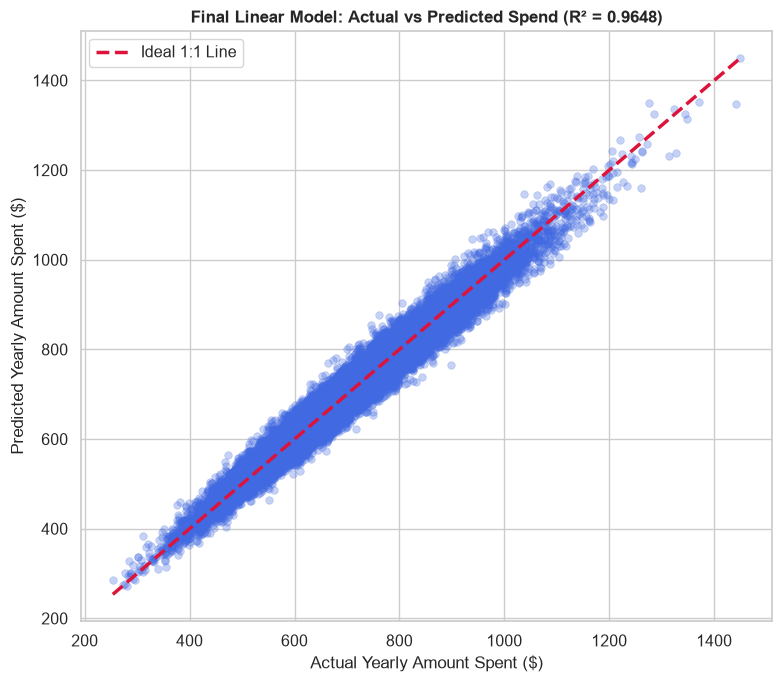

In [12]:
final_lr = LinearRegression().fit(df[parsimonious_features], y)
y_pred_final = final_lr.predict(df[parsimonious_features])

fig, ax = plt.subplots(figsize=(8, 7))
sns.scatterplot(x=y, y=y_pred_final, alpha=0.3, color='royalblue', edgecolor=None, s=30, ax=ax)
min_v = min(y.min(), y_pred_final.min())
max_v = max(y.max(), y_pred_final.max())
ax.plot([min_v, max_v], [min_v, max_v], color='crimson', linestyle='--', linewidth=2.5, label='Ideal 1:1 Line')
ax.set_title(f"Final Linear Model: Actual vs Predicted Spend (R² = {r2_score(y, y_pred_final):.4f})", fontweight='bold')
ax.set_xlabel("Actual Yearly Amount Spent ($)")
ax.set_ylabel("Predicted Yearly Amount Spent ($)")
ax.legend()
plt.tight_layout()
plt.savefig("actual_vs_predicted_linear_regression.png", dpi=300)
plt.show()
